In [69]:
%load_ext autoreload
%autoreload 2

import jax
jax.config.update("jax_enable_x64", True)

from mGST.low_level_jit import cost_function_jax_mps
from mGST.utility_functions_comparisons import GSTConfiguration, get_full_mgst_parameters_from_configuration, get_compressed_rep_from_mgst_output, get_initial_gate_set_for_optimization
from mGST.trust_region import run_riemannian_optimization, are_all_tensors_in_gate_set_isometries
from mGST.typing import OperatorSchedule, TrustRegionOptions
from mGST.visualization import plot_cost_function
from mGST.additional_fns import perturbed_target_init

from mGST.algorithm import run_mGST
import jax.numpy as jnp
import numpy as np

backend = "iqmfakeapollo"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Data Generation

In [2]:
num_qubits = 2
dim = 2**num_qubits
num_circuits = 1000
num_shots = 1000
kraus_rank = 4
num_povm = dim # full

CONFIG = GSTConfiguration(
    qubit_layouts=[[0, 1]],
    gate_set="2QXYICZ",
    num_circuits=num_circuits,
    shots=num_shots,
    rank=kraus_rank,
)

kraus_tensor_mgst, kraus_mgst, povm_mgst, state_mgst, prob_matrix, indices_list, additional_mgst_vars = get_full_mgst_parameters_from_configuration(
    CONFIG, backend, only_jax_variables=False
)

kraus_tensor_target, povm_psd_target, state_psd_target = get_compressed_rep_from_mgst_output(kraus_mgst, povm_mgst, state_mgst, kraus_rank=kraus_rank, state_rank=dim, povm_rank=dim)

2026-10-20 18:02:21,897 - iqm.benchmarks.logging_config - INFO - Generating 1000 random GST circuits
2026-10-20 18:02:22,590 - iqm.benchmarks.logging_config - INFO - Will transpile all 1000 circuits according to fixed physical layout
2026-10-20 18:02:22,985 - iqm.benchmarks.logging_config - INFO - Transpiling for backend IQMFakeApolloBackend with optimization level 0, sabre routing method all circuits
2026-10-20 18:02:26,433 - iqm.benchmarks.logging_config - INFO - Submitting batch with 1000 circuits corresponding to qubits [0, 1]
2026-10-20 18:02:26,447 - iqm.benchmarks.logging_config - INFO - Stored jobs for 1 layouts in dataset
2026-10-20 18:02:26,519 - iqm.benchmarks.logging_config - INFO - Now executing the corresponding circuit batch
2026-10-20 18:02:26,544 - iqm.benchmarks.logging_config - INFO - Retrieving all counts
2026-10-20 18:02:27,683 - iqm.benchmarks.logging_config - INFO - Adding counts to dataset
2026-10-20 18:02:29,968 - iqm.benchmarks.logging_config - INFO - Run comp

## Init operators

In [3]:
state_rank = dim # max
povm_rank = dim # max

target_gate_set_superops = {
    "kraus": kraus_mgst,
    "povm": povm_mgst,
    "state": state_mgst
}


# 2. Initiallization
init_gate_set_psd = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    project_kraus_to_isometry=True,
)

cost_fn_kwargs = {
    "indices_list": indices_list,
    "prob_matrix": prob_matrix,
    "jit": True,
    "use_log_likelihood": True,
    "verbose": False,  # we don't want to print during the cost function evaluation
    "num_shots": num_shots,
}

In [4]:
num_gates = kraus_tensor_target.shape[0]
mgst_args = [prob_matrix, additional_mgst_vars["J"], None, num_gates, dim**2, kraus_rank, num_povm, additional_mgst_vars["bsize"], num_shots] 

initial_gate_set_mgst = {op_name: np.array(op) for op_name, op in target_gate_set_superops.items()}

kraus_init_mgst = perturbed_target_init(initial_gate_set_mgst["kraus"], kraus_rank, seed=42)
init_ops_mgst = [kraus_init_mgst, initial_gate_set_mgst["povm"], initial_gate_set_mgst["state"]]

In [104]:
num_gates

6

# Optimization

In [5]:
num_iterations_outer = 20
num_iterations_tr = 5
num_iterations_cg = 10 
tol_grad = 1e-8 # it was 1e-4 before. 1e-8 is suggested in the book.
relative_precision = 1e-8 # changing to the default value of mGST.
global_gradient_norm_tol = 1e-10


tr_schedule_povm_state = OperatorSchedule.default(num_iterations_outer, TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, linearize=False, radius_init=1e-3))

tr_schedule_kraus = OperatorSchedule.default(num_iterations_outer, TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, linearize=False, radius_init=1e-1))

optimization_schedule = {
    "kraus": tr_schedule_kraus,
    "povm": tr_schedule_povm_state,
    "state": tr_schedule_povm_state
}

optimization_options = {
    "optimization_schedule": optimization_schedule,
    "num_iterations": num_iterations_outer,
    "relative_precision": 1e-3, # changed due to the changes in convergence criteria
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "carry_over_radius": True,
}

In [57]:
optimized_operators_jax, cost_fn_history_jax, convergence_reason_jax = run_riemannian_optimization(
    *init_gate_set_psd.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    use_jit=True,
    jit_contraction="prefix",
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.100760e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 1.146524e+06. |r∇f(x)|: 6.808083e+08. Radius: 1.00e-03
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: 2.452812e-03 < 1.250000e-01
TR Iteration: 1. f(x): 1.146524e+06. |r∇f(x)|: 6.808083e+08. Radius: 2.50e-04
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected

In [7]:
mgst_max_iters_sfn = 10 # to test if it even goes there
mgst_max_iters_gd = 80 # gradient descent takes a long time to converge
mgst_target_rel_prec = 1e-8

2026-10-20 20:12:52,294 - iqm.benchmarks.logging_config - INFO - Starting mGST optimization...
100%|██████████| 80/80 [01:44<00:00,  1.31s/it]

Reached maximum iterations (80) without convergence.


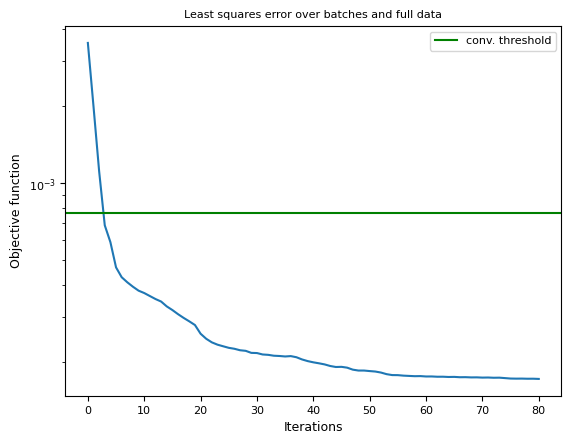

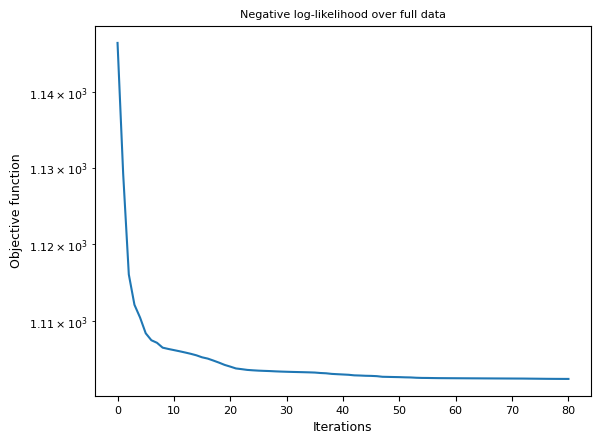

2026-10-20 20:14:37,073 - iqm.benchmarks.logging_config - INFO - Convergence criterion satisfied
2026-10-20 20:14:37,075 - iqm.benchmarks.logging_config - INFO - Final objective 1.72e-4 in time 104.79s


In [9]:
*optimized_operators_mgst, cost_fn_history_mgst = run_mGST(
    *mgst_args,
    init = init_ops_mgst,
    method = "GD",
    final_iter=mgst_max_iters_gd,
    target_rel_prec=mgst_target_rel_prec,
    return_operators_list=False,
    verbose_level=2,
    optimize_over_log_likelihood=True
)

In [ ]:
# ffs, this shit gives a `nan` error AGAIN in the same iteration (5th). 
# Requires further investigation, but not right now.
*optimized_operators_mgst_sfn_log, cost_fn_history_mgst_sfn_log = run_mGST(
    *mgst_args,
    init = init_ops_mgst,
    method = "SFN",
    final_iter=mgst_max_iters_sfn,
    target_rel_prec=mgst_target_rel_prec,
    return_operators_list=False,
    verbose_level=2,
    optimize_over_log_likelihood=True,
)

2026-10-20 20:54:08,164 - iqm.benchmarks.logging_config - INFO - Starting mGST optimization...
 50%|█████     | 5/10 [06:52<06:52, 82.57s/it]


ValueError: array must not contain infs or NaNs

In [30]:
import numpy as np

np.savez_compressed(
    "mgst_sfn_repro.npz",
    **{f"arg_{i}": np.asarray(value)
       for i, value in enumerate(mgst_args) if i != 2},
    K=np.asarray(init_ops_mgst[0]),
    E=np.asarray(init_ops_mgst[1]),
    rho=np.asarray(init_ops_mgst[2]),
    final_iter=int(mgst_max_iters_sfn),
    target_rel_prec=float(mgst_target_rel_prec),
)

2026-10-21 11:40:37,113 - iqm.benchmarks.logging_config - INFO - Starting mGST optimization...
100%|██████████| 10/10 [12:55<00:00, 77.57s/it]


Reached maximum iterations (10) without convergence.


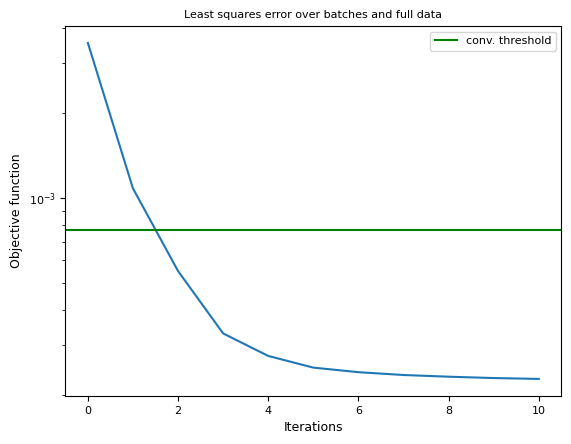

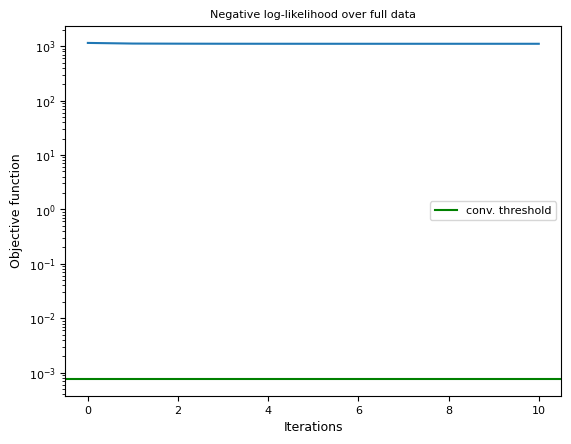

2026-10-21 11:53:33,374 - iqm.benchmarks.logging_config - INFO - Convergence criterion satisfied
2026-10-21 11:53:33,376 - iqm.benchmarks.logging_config - INFO - Final objective 2.28e-4 in time 776.26s


In [24]:
*optimized_operators_mgst_sfn, cost_fn_history_mgst_sfn = run_mGST(
    *mgst_args,
    init = init_ops_mgst,
    method = "SFN",
    final_iter=mgst_max_iters_sfn,
    target_rel_prec=mgst_target_rel_prec,
    return_operators_list=False,
    verbose_level=2,
    optimize_over_log_likelihood=False,
)

---
# Interior SPAM initialization

The target state and POVM are pure/projective. Factorized at full rank, their extra columns are ~1e-7 (only the `1e-14·I` regularization). This puts the initial point on the boundary of the PSD cone:
- predicted probabilities ~0 where the data is not → huge log-likelihood gradient, quadratic model valid only within ~√p,
- zero columns have zero gradient → saddle of the factorization (tCG hits negative curvature at its first iteration).

Both force tiny trust region radii, so State and POVM barely move during the first outer iterations (see the baseline run above).

Here the identity is mixed into the targets before factorizing: $E_i \to (1-\varepsilon)E_i + \varepsilon I/n_\mathrm{povm}$, $\rho \to (1-\varepsilon)\rho + \varepsilon I/d$. The same reason is why the non-dominant Kraus operators already start as small random matrices (`perturbed_target_init`). See `README_rtr_initial_iterations.md`.

In [12]:
spam_depolarization = 1e-2

init_gate_set_psd_interior = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    # the rank-4 truncation of the perturbed (full-rank) channel leaves |sum K^†K - I| ~ 5e-6
    project_kraus_to_isometry=True,
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_interior))
print("Initial cost (target SPAM init):  ", cost_function_jax_mps(*init_gate_set_psd.values(), **cost_fn_kwargs))
print("Initial cost (interior SPAM init):", cost_function_jax_mps(*init_gate_set_psd_interior.values(), **cost_fn_kwargs))

All isometries: True
Initial cost (target SPAM init):   1146523.899706518
Initial cost (interior SPAM init): 1135351.7796902426


In [13]:
# Same options as the baseline run above, only the initial POVM and state differ.
optimized_operators_jax_interior, cost_fn_history_jax_interior, convergence_reason_jax_interior = run_riemannian_optimization(
    *init_gate_set_psd_interior.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    use_jit=True,
    jit_contraction="prefix",
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.100760e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 1.135352e+06. |r∇f(x)|: 5.511843e+04. Radius: 1.00e-03
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
TR Iteration: 1. f(x): 1.135297e+06. |r∇f(x)|: 5.512281e+04. Radius: 2.00e-03
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
TR Iteration: 2. f(x): 1.135186e+06. |r∇f(x)|: 5.513251e+04. Radius: 4.00e-03
TC

# Testing a few heuristics for the initial and max radius

In [31]:
optimized_operators_jax_interior.keys()

dict_keys(['kraus', 'povm', 'state'])

In [53]:
from mGST.utility_functions_comparisons import get_isometry_dimensions_from_tensor

def get_typical_distance(tensor: jnp.ndarray, operator_type: str) -> float:
    """Riemannian 'typical distance' of the (product of) Stiefel manifold(s).

    Every X in St(n, p) satisfies ||X||_F = sqrt(p), so the manifold sits on a
    sphere of radius sqrt(p) and its diameter is O(sqrt(p)). For a stack of
    ``num_factors`` independent Stiefel factors the squared norms add up.
    """
    n, p = get_isometry_dimensions_from_tensor(tensor, operator_type)
    print("n", n, "p", p)
    num_factors = tensor.shape[0] if operator_type == "kraus" else 1
    return jnp.sqrt(num_factors * p)

def compute_radius_heuristics(tensor: jnp.ndarray, operator_type: str, heuristic: str = "pymanopt")->tuple[float, float]:
    typical_distance = get_typical_distance(tensor, operator_type)
    print("typical_distance", typical_distance)
    if heuristic == "pymanopt":
        initial_radius = typical_distance / 8
        max_radius = typical_distance
    else:
        raise ValueError(f"Unknown heuristic: {heuristic}")
    return initial_radius, max_radius
    
radii_per_operator = {op_type: compute_radius_heuristics(optimized_operators_jax_interior[op_type], op_type) for op_type in optimized_operators_jax_interior}

heuristic_schedules = {}
for op_type in optimized_operators_jax_interior:
    init_radius, max_radius = radii_per_operator[op_type]
    tr_options = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_init=init_radius, max_radius=max_radius)
    heuristic_schedules[op_type] = OperatorSchedule.default(num_iterations_outer, tr_options)

optimization_opts_heuristic = optimization_options.copy()
optimization_opts_heuristic["optimization_schedule"] = heuristic_schedules

radii_per_operator


n 16 p 4
typical_distance 4.898979485566356
n 16 p 4
typical_distance 2.0
n 16 p 1
typical_distance 1.0


{'kraus': (Array(0.61237244, dtype=float64, weak_type=True),
  Array(4.89897949, dtype=float64, weak_type=True)),
 'povm': (Array(0.25, dtype=float64, weak_type=True),
  Array(2., dtype=float64, weak_type=True)),
 'state': (Array(0.125, dtype=float64, weak_type=True),
  Array(1., dtype=float64, weak_type=True))}

In [56]:
optimized_operators_heuristic, cost_fn_history_heuristic, convergence_reason_heuristic = run_riemannian_optimization(
    *init_gate_set_psd_interior.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    use_jit=True,
    jit_contraction="prefix",
    **optimization_opts_heuristic,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.100760e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
TR Iteration: 0. f(x): 1.135352e+06. |r∇f(x)|: 5.511843e+04. Radius: 2.50e-01
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
TR Iteration: 1. f(x): 1.123636e+06. |r∇f(x)|: 4.216297e+04. Radius: 5.00e-01
TCG finished after: 1/10 iters. 
 Reason: Exceeded trust region boundary 📈.
---------------------------------------
Update rejected ❌. Quality quotient: 6.952666e-02 < 1.250000e-01
TR Iteration: 2

In [71]:
from mGST.typing import TrustRegionOptions

In [76]:
tr_options_distance = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_heuristic="typical_distance")
schedule_distance = OperatorSchedule.default(num_iterations_outer, tr_options_distance)
schedules_distance_ops = {op: schedule_distance for op in init_gate_set_psd_interior.keys()}

optimization_opts_distance = optimization_options.copy()
optimization_opts_distance["optimization_schedule"] = schedules_distance_ops
optimization_opts_distance

{'optimization_schedule': {'kraus': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=True, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=True, linearize=False, radius_heuristic='typical_distance'))]),
  'povm': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=True, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=True, linearize=False, radius_heuristic='typical_distance'))]),
  'state': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=True, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=

In [77]:
optimized_operators_distance, cost_fn_history_distance, convergence_reason_distance = run_riemannian_optimization(
    *init_gate_set_psd_interior.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    use_jit=True,
    jit_contraction="prefix",
    **optimization_opts_distance,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.100760e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (typical_distance heuristic): Δ0 = 2.50e-01. Δmax = 2.00e+00
TR Iteration: 0. f(x): 1.135352e+06. |r∇f(x)|: 5.511843e+04. Radius: 2.50e-01
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
TR Iteration: 1. f(x): 1.123636e+06. |r∇f(x)|: 4.216297e+04. Radius: 5.00e-01
TCG finished after: 1/10 iters. 
 Reason: Exceeded trust region boundary 📈.
---------------------------------------
Update reject

In [72]:
tr_options_gradient = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=True, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_heuristic="gradient")
schedule_gradient = OperatorSchedule.default(num_iterations_outer, tr_options_gradient)
schedules_gradient_ops = {op: schedule_gradient for op in init_gate_set_psd_interior.keys()}

optimization_opts_gradient = optimization_options.copy()
optimization_opts_gradient["optimization_schedule"] = schedules_gradient_ops
optimization_opts_gradient

{'optimization_schedule': {'kraus': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=True, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=True, linearize=False, radius_heuristic='gradient'))]),
  'povm': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=True, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=True, linearize=False, radius_heuristic='gradient'))]),
  'state': OperatorSchedule(items=[OptimizationScheduleItem(start=0, end=19, options=TrustRegionOptions(metric='euclidean', verbose=True, num_iterations=5, radius_init=None, max_radius=None, quotient_trust=0.125, tol_grad=1e-08, num_iterations_cg=10, theta_cg=1, kappa_cg=0.1, verbose_cg=

In [73]:
optimized_operators_gradient, cost_fn_history_gradient, convergence_reason_gradient = run_riemannian_optimization(
    *init_gate_set_psd_interior.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    use_jit=True,
    jit_contraction="prefix",
    **optimization_opts_gradient,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.100760e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (gradient heuristic): Δ0 = 2.00e+00. Δmax = 2.00e+00
TR Iteration: 0. f(x): 1.135352e+06. |r∇f(x)|: 5.511843e+04. Radius: 2.00e+00
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
Update rejected ❌. Quality quotient: -1.472183e+00 < 1.250000e-01
TR Iteration: 1. f(x): 1.135352e+06. |r∇f(x)|: 5.511843e+04. Radius: 5.00e-01
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountere

# Visualization

In [14]:
title_init = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Shots: {num_shots} | Num. Sequences: {num_circuits}"

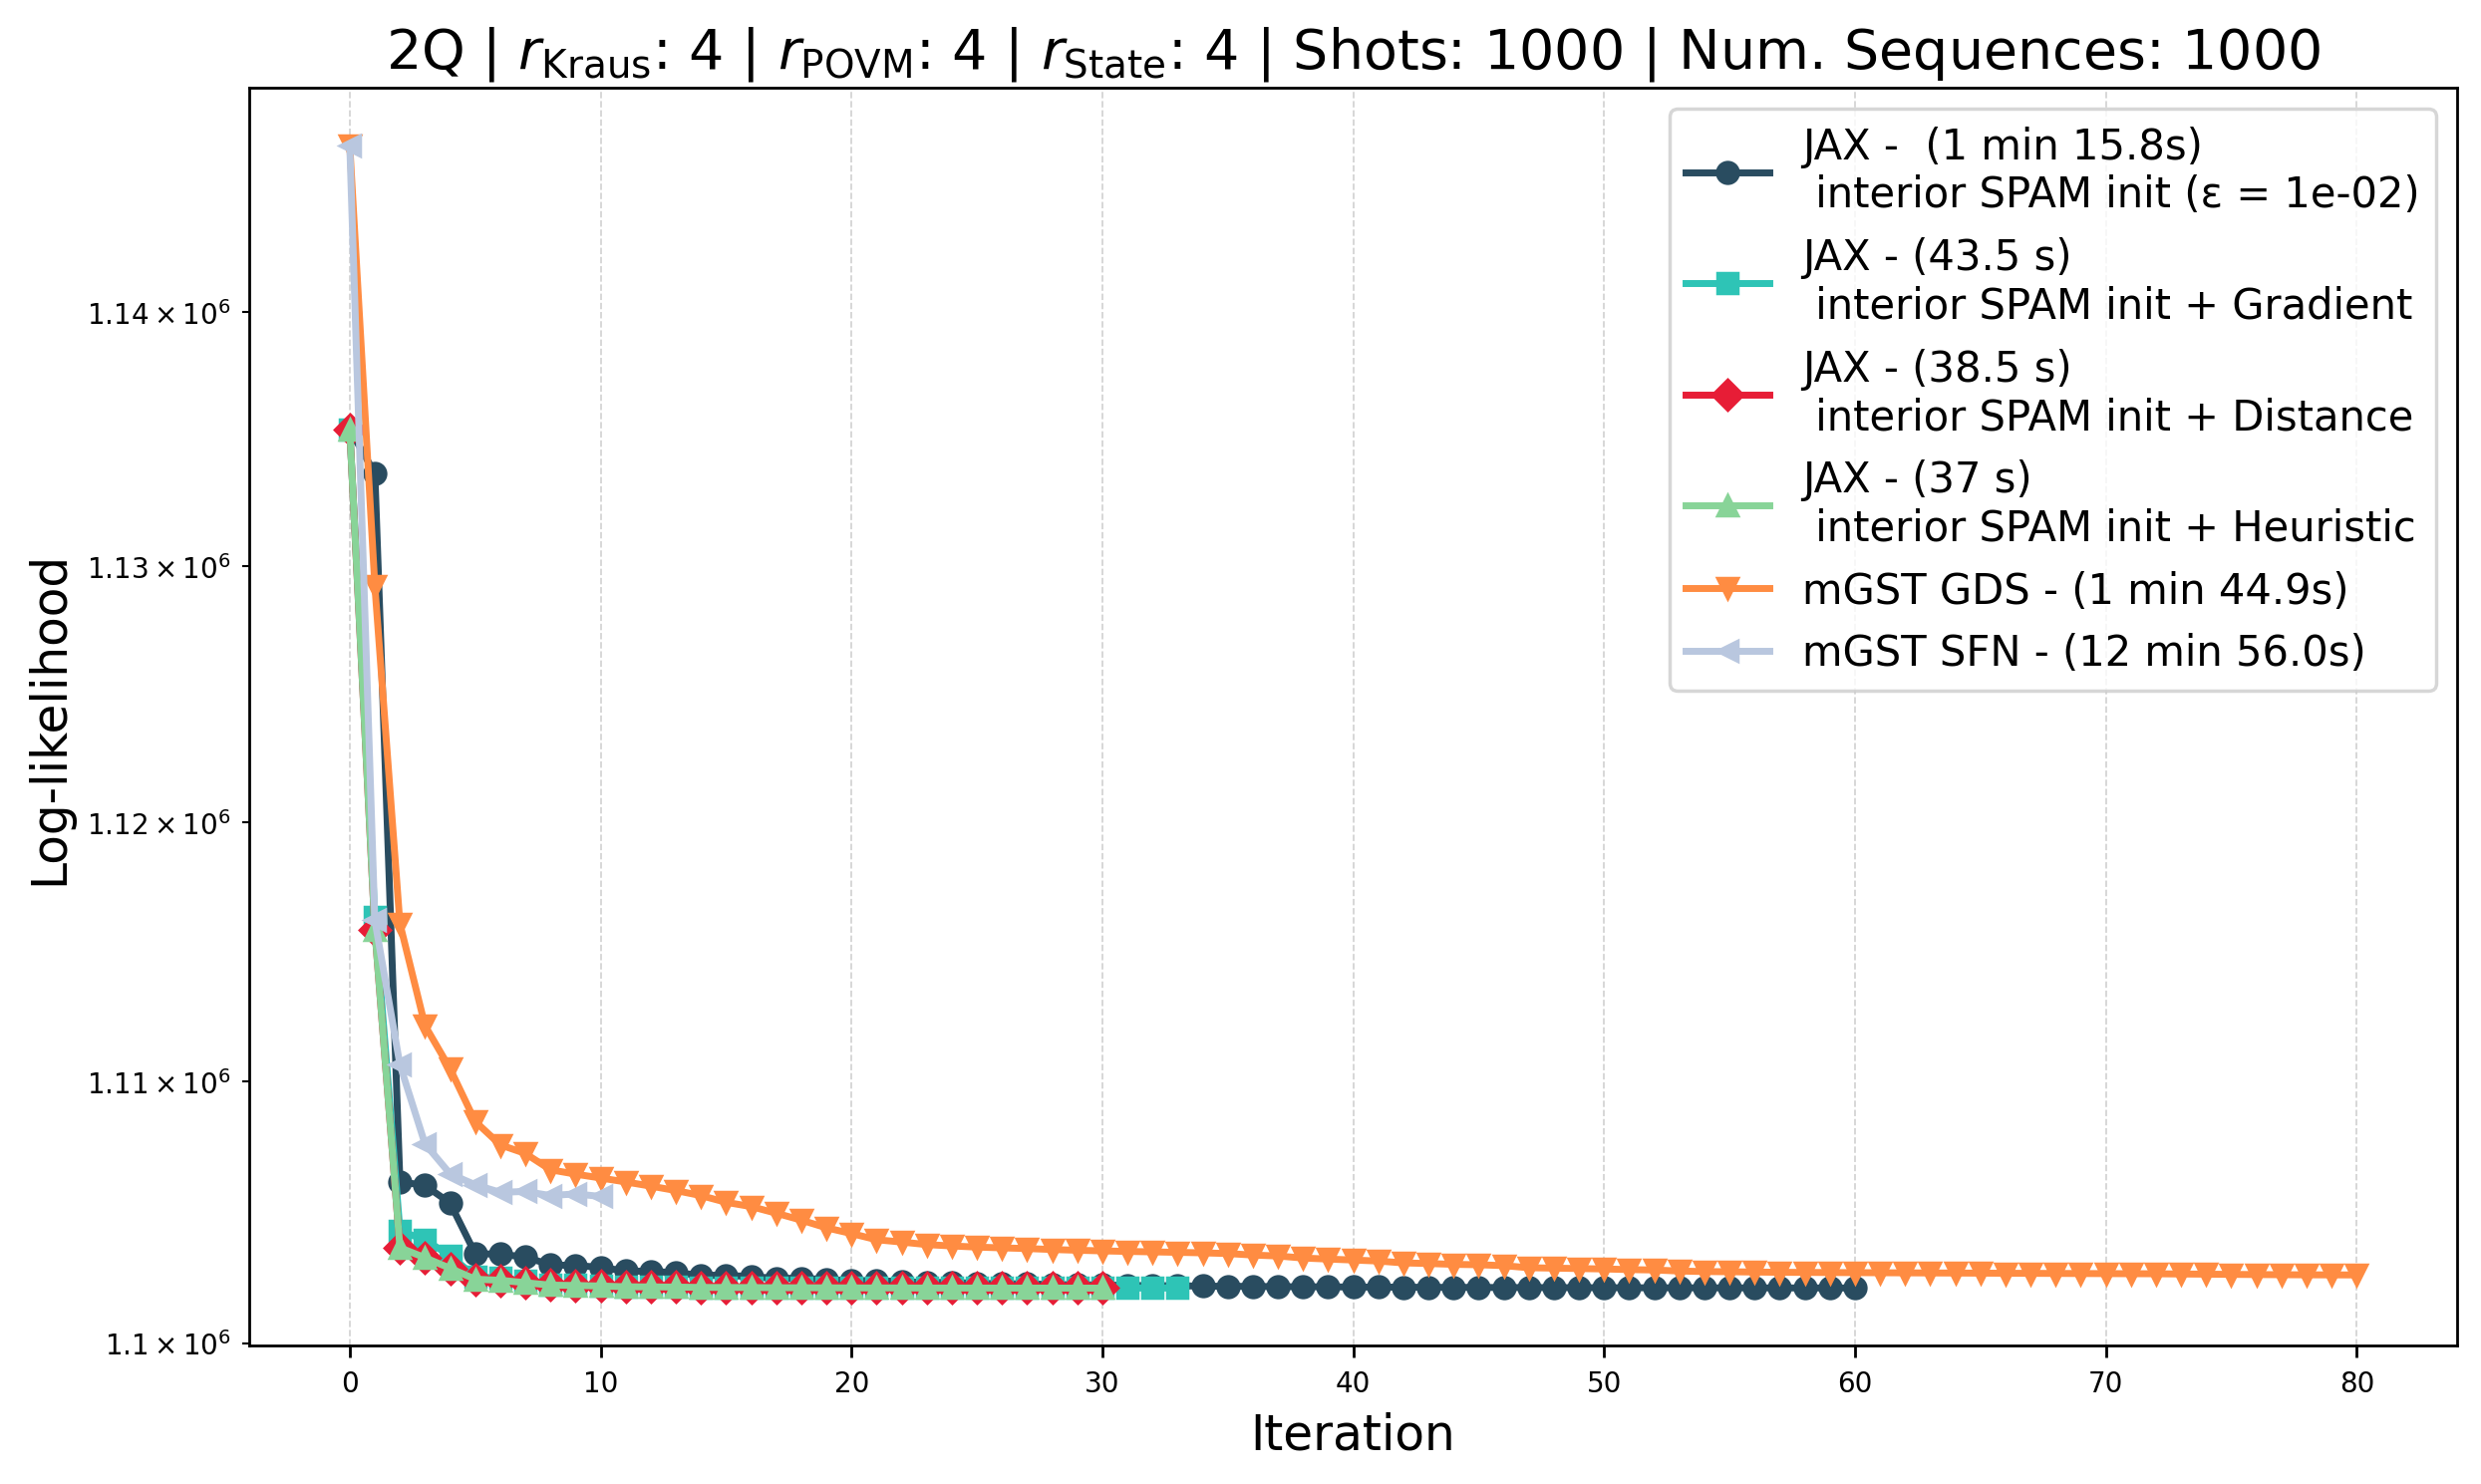

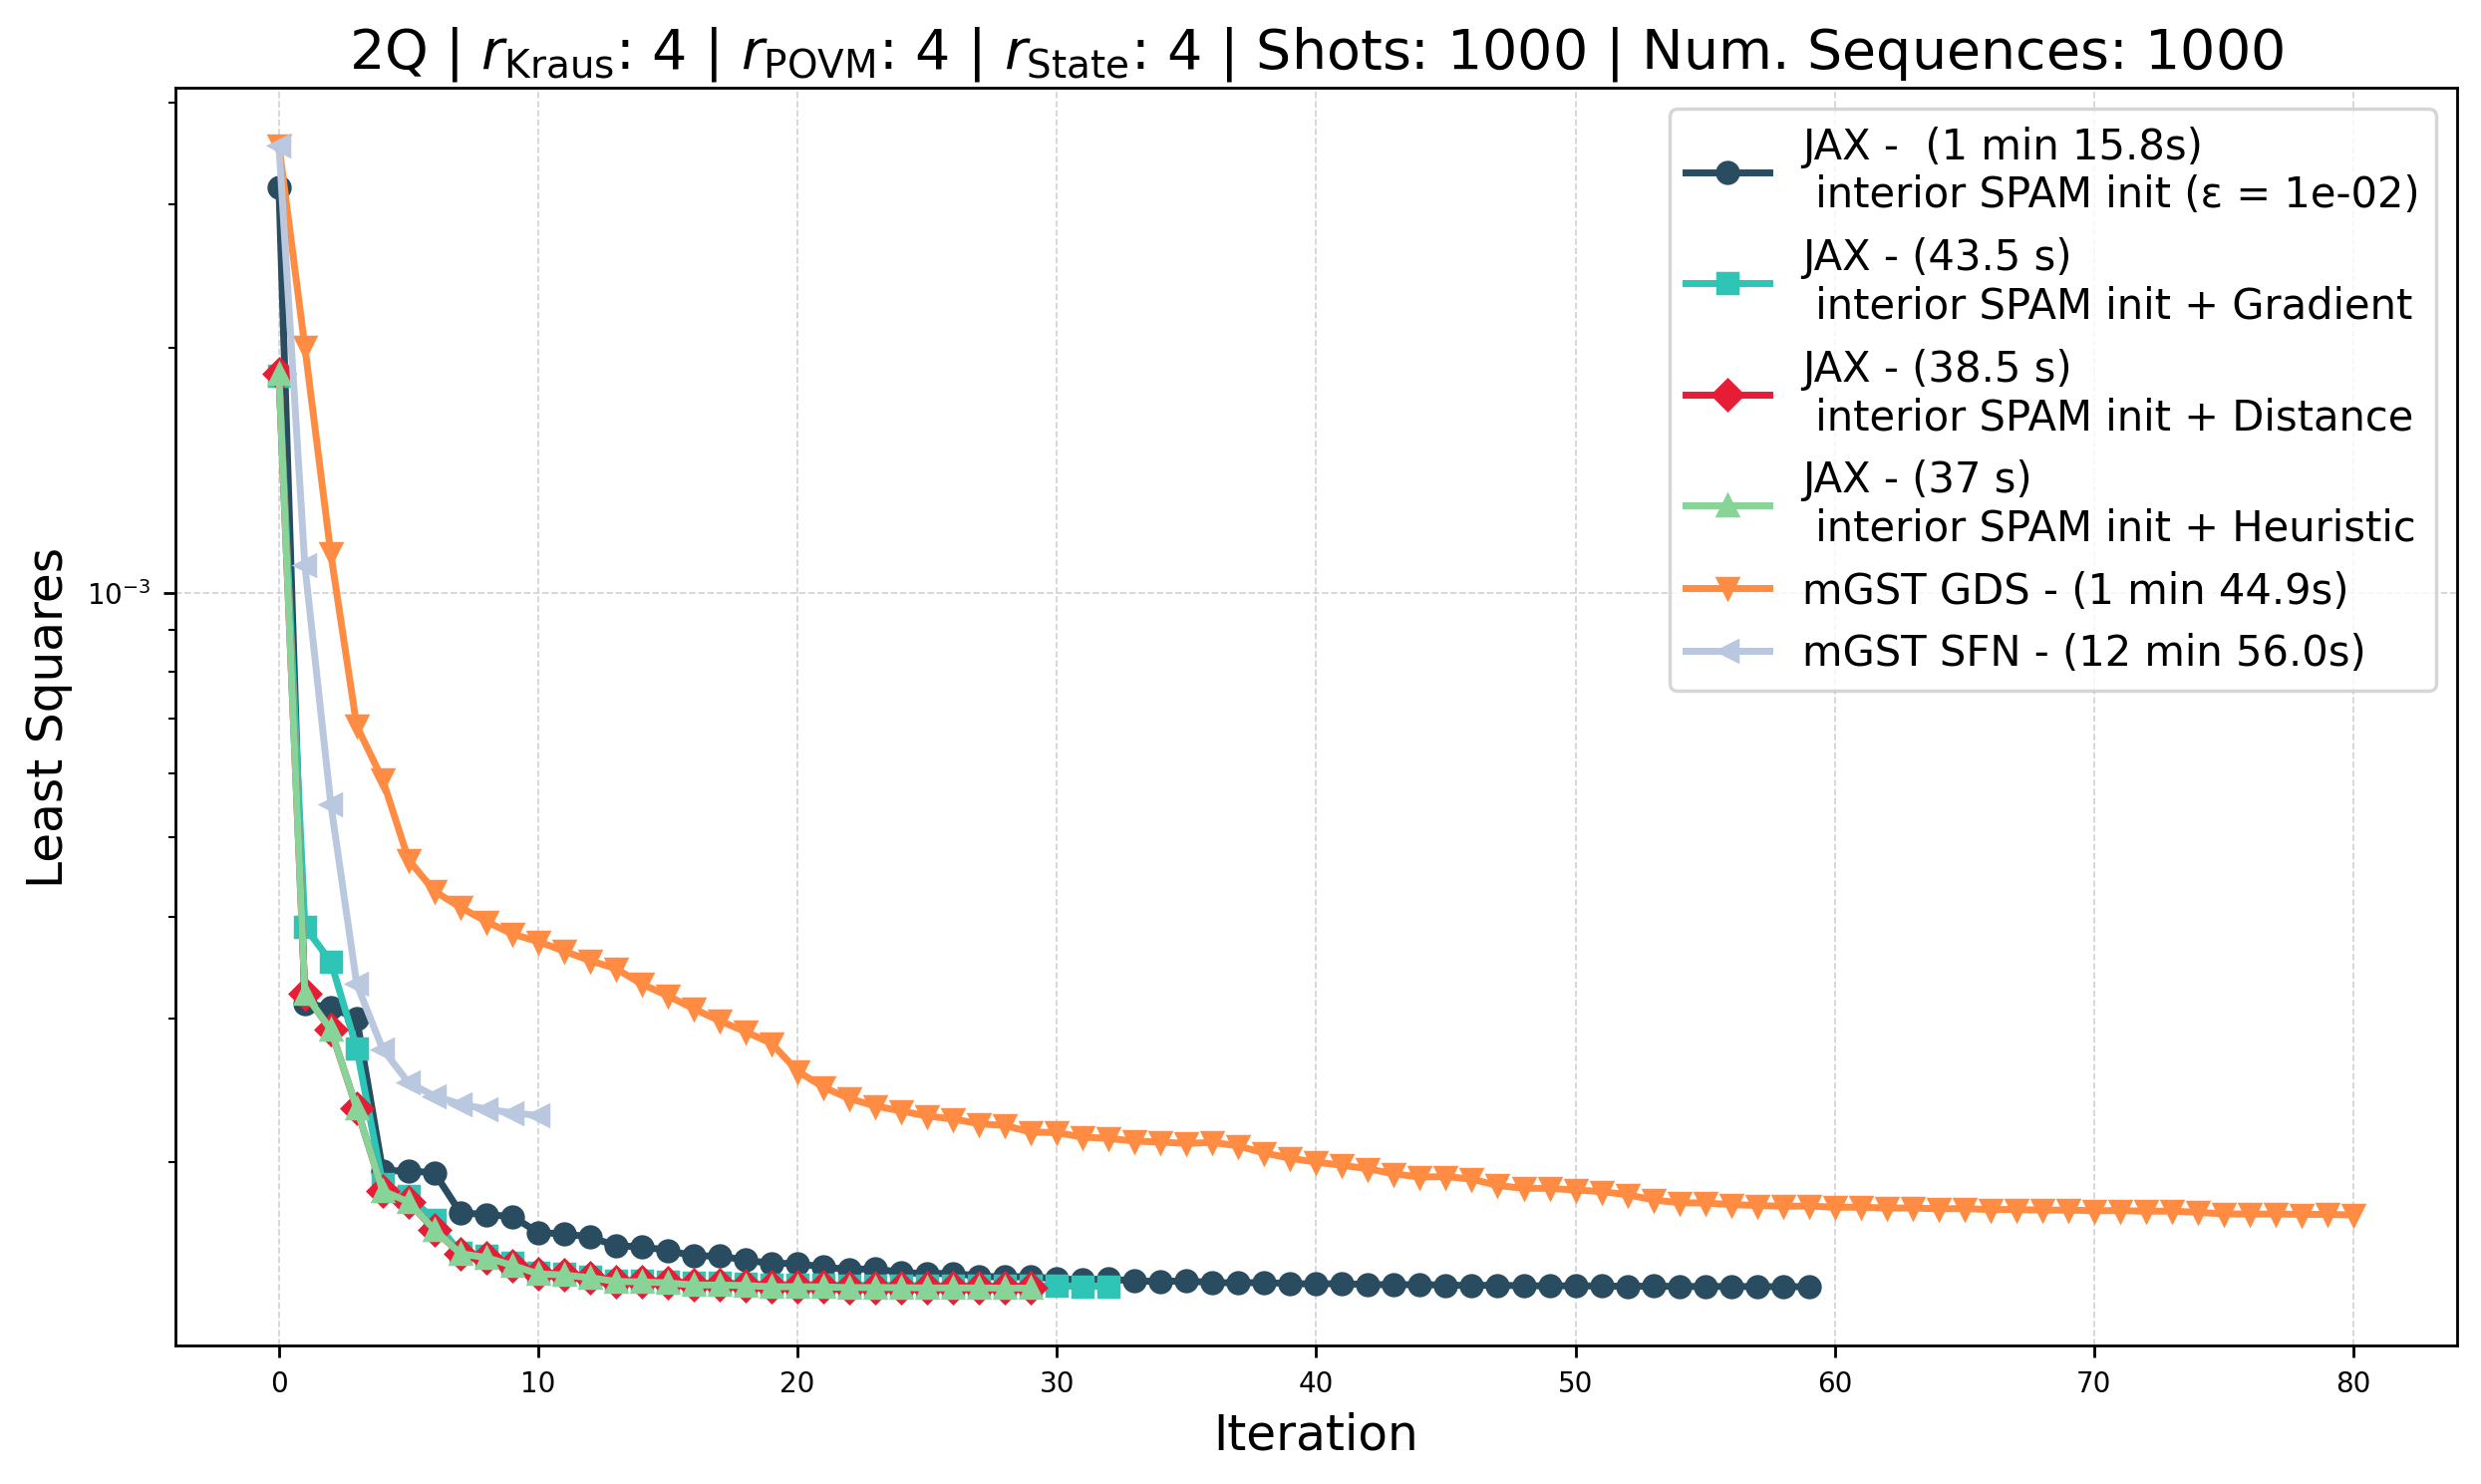

In [84]:
cost_fns_log_likelihood_interior = [
    # cost_fn_history_jax["main"],
    cost_fn_history_jax_interior["main"],
    cost_fn_history_gradient["main"],
    cost_fn_history_distance["main"],
    cost_fn_history_heuristic["main"],
    jnp.array(cost_fn_history_mgst["log_likelihood"])*num_shots,
    jnp.array(cost_fn_history_mgst_sfn["log_likelihood"])*num_shots,
]
cost_fns_least_squares_interior = [
    # cost_fn_history_jax["least_squares"],
    cost_fn_history_jax_interior["least_squares"],
    cost_fn_history_gradient["least_squares"],
    cost_fn_history_distance["least_squares"],
    cost_fn_history_heuristic["least_squares"],
    cost_fn_history_mgst["least_squares"],
    cost_fn_history_mgst_sfn["least_squares"],
]
labels_interior = [
    # "JAX -  (1 min 16.8s) \n target SPAM init",
    f"JAX -  (1 min 15.8s) \n interior SPAM init (ε = {spam_depolarization:.0e})",
    "JAX - (43.5 s) \n interior SPAM init + Gradient",
    "JAX - (38.5 s) \n interior SPAM init + Distance",
    "JAX - (37 s) \n interior SPAM init + Heuristic",
    "mGST GDS - (1 min 44.9s)",
    "mGST SFN - (12 min 56.0s)"
]

plot_cost_function(cost_fns_log_likelihood_interior, title=title_init, labels=labels_interior, ylabel="Log-likelihood")
plot_cost_function(cost_fns_least_squares_interior, title=title_init, labels=labels_interior, ylabel="Least Squares")

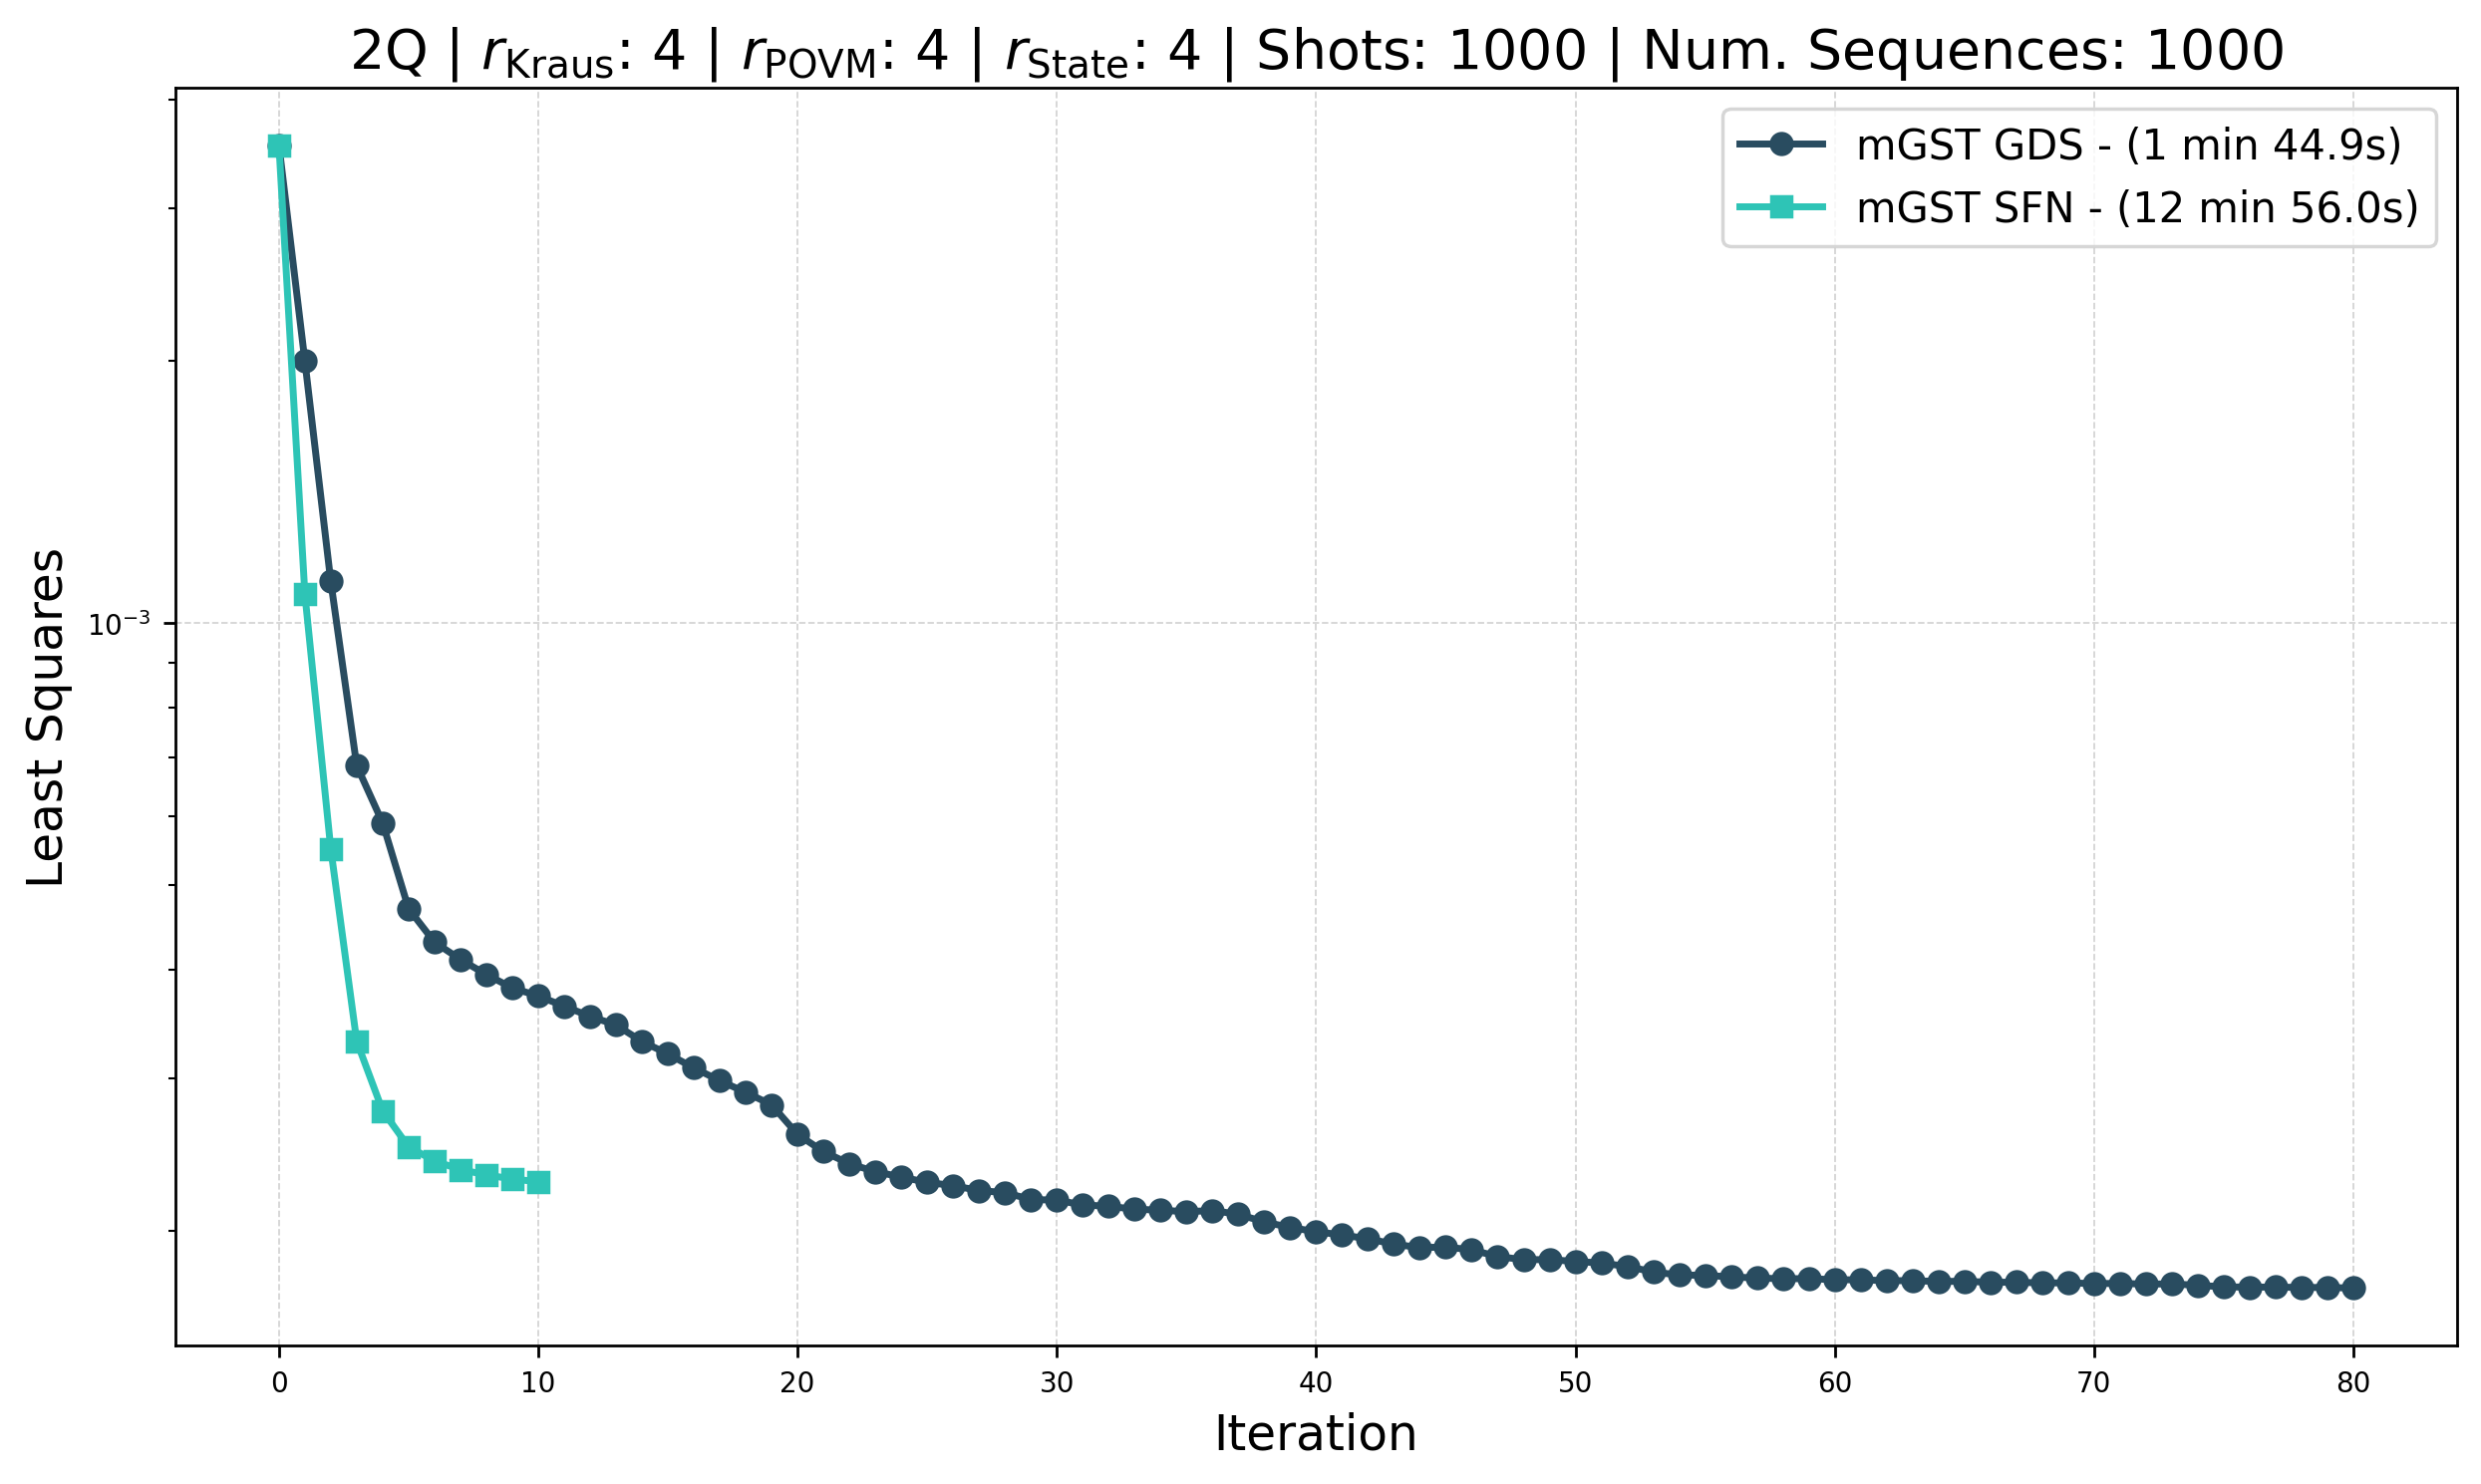

In [29]:
plot_cost_function(cost_fns_least_squares_interior[-2:], title=title_init, labels=labels_interior[-2:], ylabel="Least Squares")

# Repeat everything with rank 16

In [88]:
# 2. Initiallization
max_kraus_rank = dim**2
    
init_gate_set_psd_max_rank = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=max_kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=False, # because it is max rank, even false would return an isometry
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_max_rank))

kraus_init_mgst_max_rank = perturbed_target_init(initial_gate_set_mgst["kraus"], max_kraus_rank, seed=42)
init_ops_mgst_max_rank = [kraus_init_mgst_max_rank, initial_gate_set_mgst["povm"], initial_gate_set_mgst["state"]]

All isometries: True


In [89]:
optimized_operators_max_rank, cost_fn_history_max_rank, convergence_reason_max_rank = run_riemannian_optimization(
    *init_gate_set_psd_max_rank.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    verbose=True,
    absolute_tolerance=1,
    use_jit=True,
    jit_contraction="prefix",
    **optimization_opts_distance,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
kraus: Schedule:
  [0-19]: TrustRegionOptions
povm: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 1.100760e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (typical_distance heuristic): Δ0 = 2.50e-01. Δmax = 2.00e+00
TR Iteration: 0. f(x): 1.125232e+06. |r∇f(x)|: 5.615246e+04. Radius: 2.50e-01
TCG finished after: 1/10 iters. 
 Reason: Negative curvature encountered 📉.
---------------------------------------
TR Iteration: 1. f(x): 1.111856e+06. |r∇f(x)|: 4.408241e+04. Radius: 2.50e-01
TCG finished after: 1/10 iters. 
 Reason: Exceeded trust region boundary 📈.
---------------------------------------
TR Iteration:

In [103]:
optimized_operators_max_rank["povm"].shape

(4, 4, 4)

In [93]:
mgst_args_max = [prob_matrix, additional_mgst_vars["J"], None, num_gates, dim**2, max_kraus_rank, num_povm, additional_mgst_vars["bsize"], num_shots] 

2026-10-21 17:59:54,051 - iqm.benchmarks.logging_config - INFO - Starting mGST optimization...
100%|██████████| 60/60 [01:23<00:00,  1.40s/it]

Reached maximum iterations (60) without convergence.


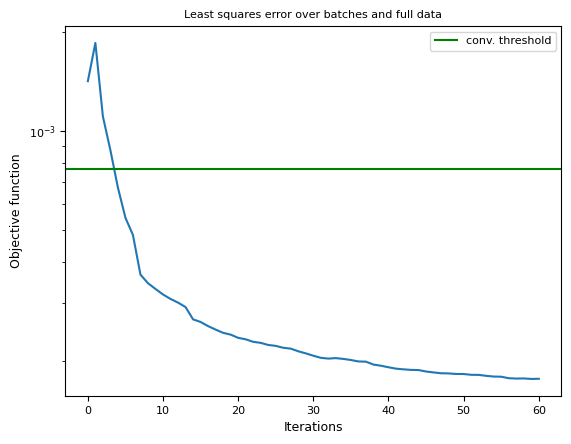

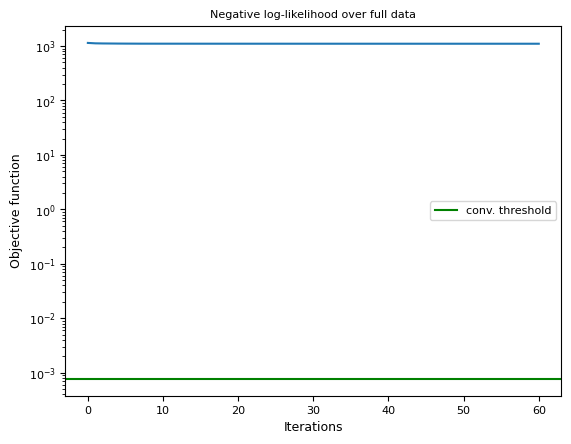

2026-10-21 18:01:18,255 - iqm.benchmarks.logging_config - INFO - Convergence criterion satisfied
2026-10-21 18:01:18,258 - iqm.benchmarks.logging_config - INFO - Final objective 1.76e-4 in time 84.21s


In [96]:
*optimized_operators_mgst_max_gds, cost_fn_history_mgst_max_gds = run_mGST(
    *mgst_args_max,
    init = init_ops_mgst_max_rank,
    method = "GD",
    final_iter=60, # reduced since before it was more or less converged at this point
    target_rel_prec=1e-6, # also reduced to see if this triggers convergence faster
    return_operators_list=False,
    verbose_level=2,
    optimize_over_log_likelihood=True
)

In [98]:
mgst_max_iters_sfn

10

2026-10-21 20:39:47,226 - iqm.benchmarks.logging_config - INFO - Starting mGST optimization...
100%|██████████| 4/4 [1:12:26<00:00, 1086.61s/it]

Reached maximum iterations (4) without convergence.


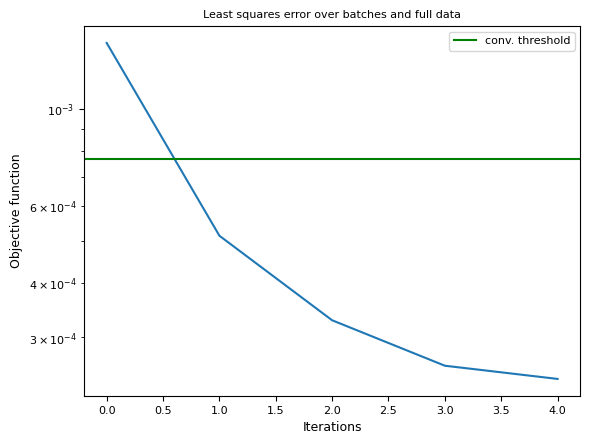

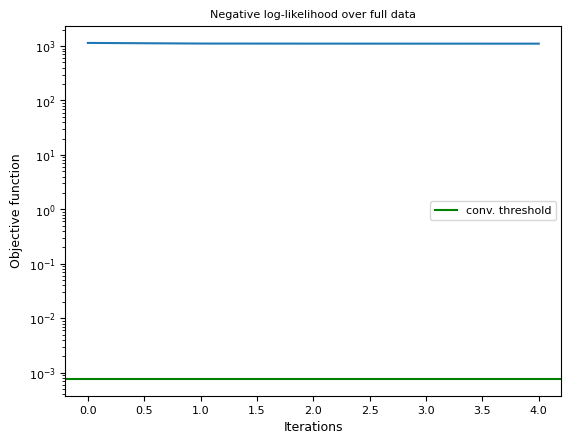

2026-10-21 21:52:14,050 - iqm.benchmarks.logging_config - INFO - Convergence criterion satisfied
2026-10-21 21:52:14,053 - iqm.benchmarks.logging_config - INFO - Final objective 2.41e-4 in time 4346.83s


In [100]:
*optimized_operators_mgst_max_sfn, cost_fn_history_mgst_max_sfn = run_mGST(
    *mgst_args_max,
    init = init_ops_mgst_max_rank,
    method = "SFN",
    final_iter=4,
    target_rel_prec=1e-6,
    return_operators_list=False,
    verbose_level=2,
    optimize_over_log_likelihood=False,
)

In [90]:
title_max = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {max_kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Shots: {num_shots} | Num. Sequences: {num_circuits}"

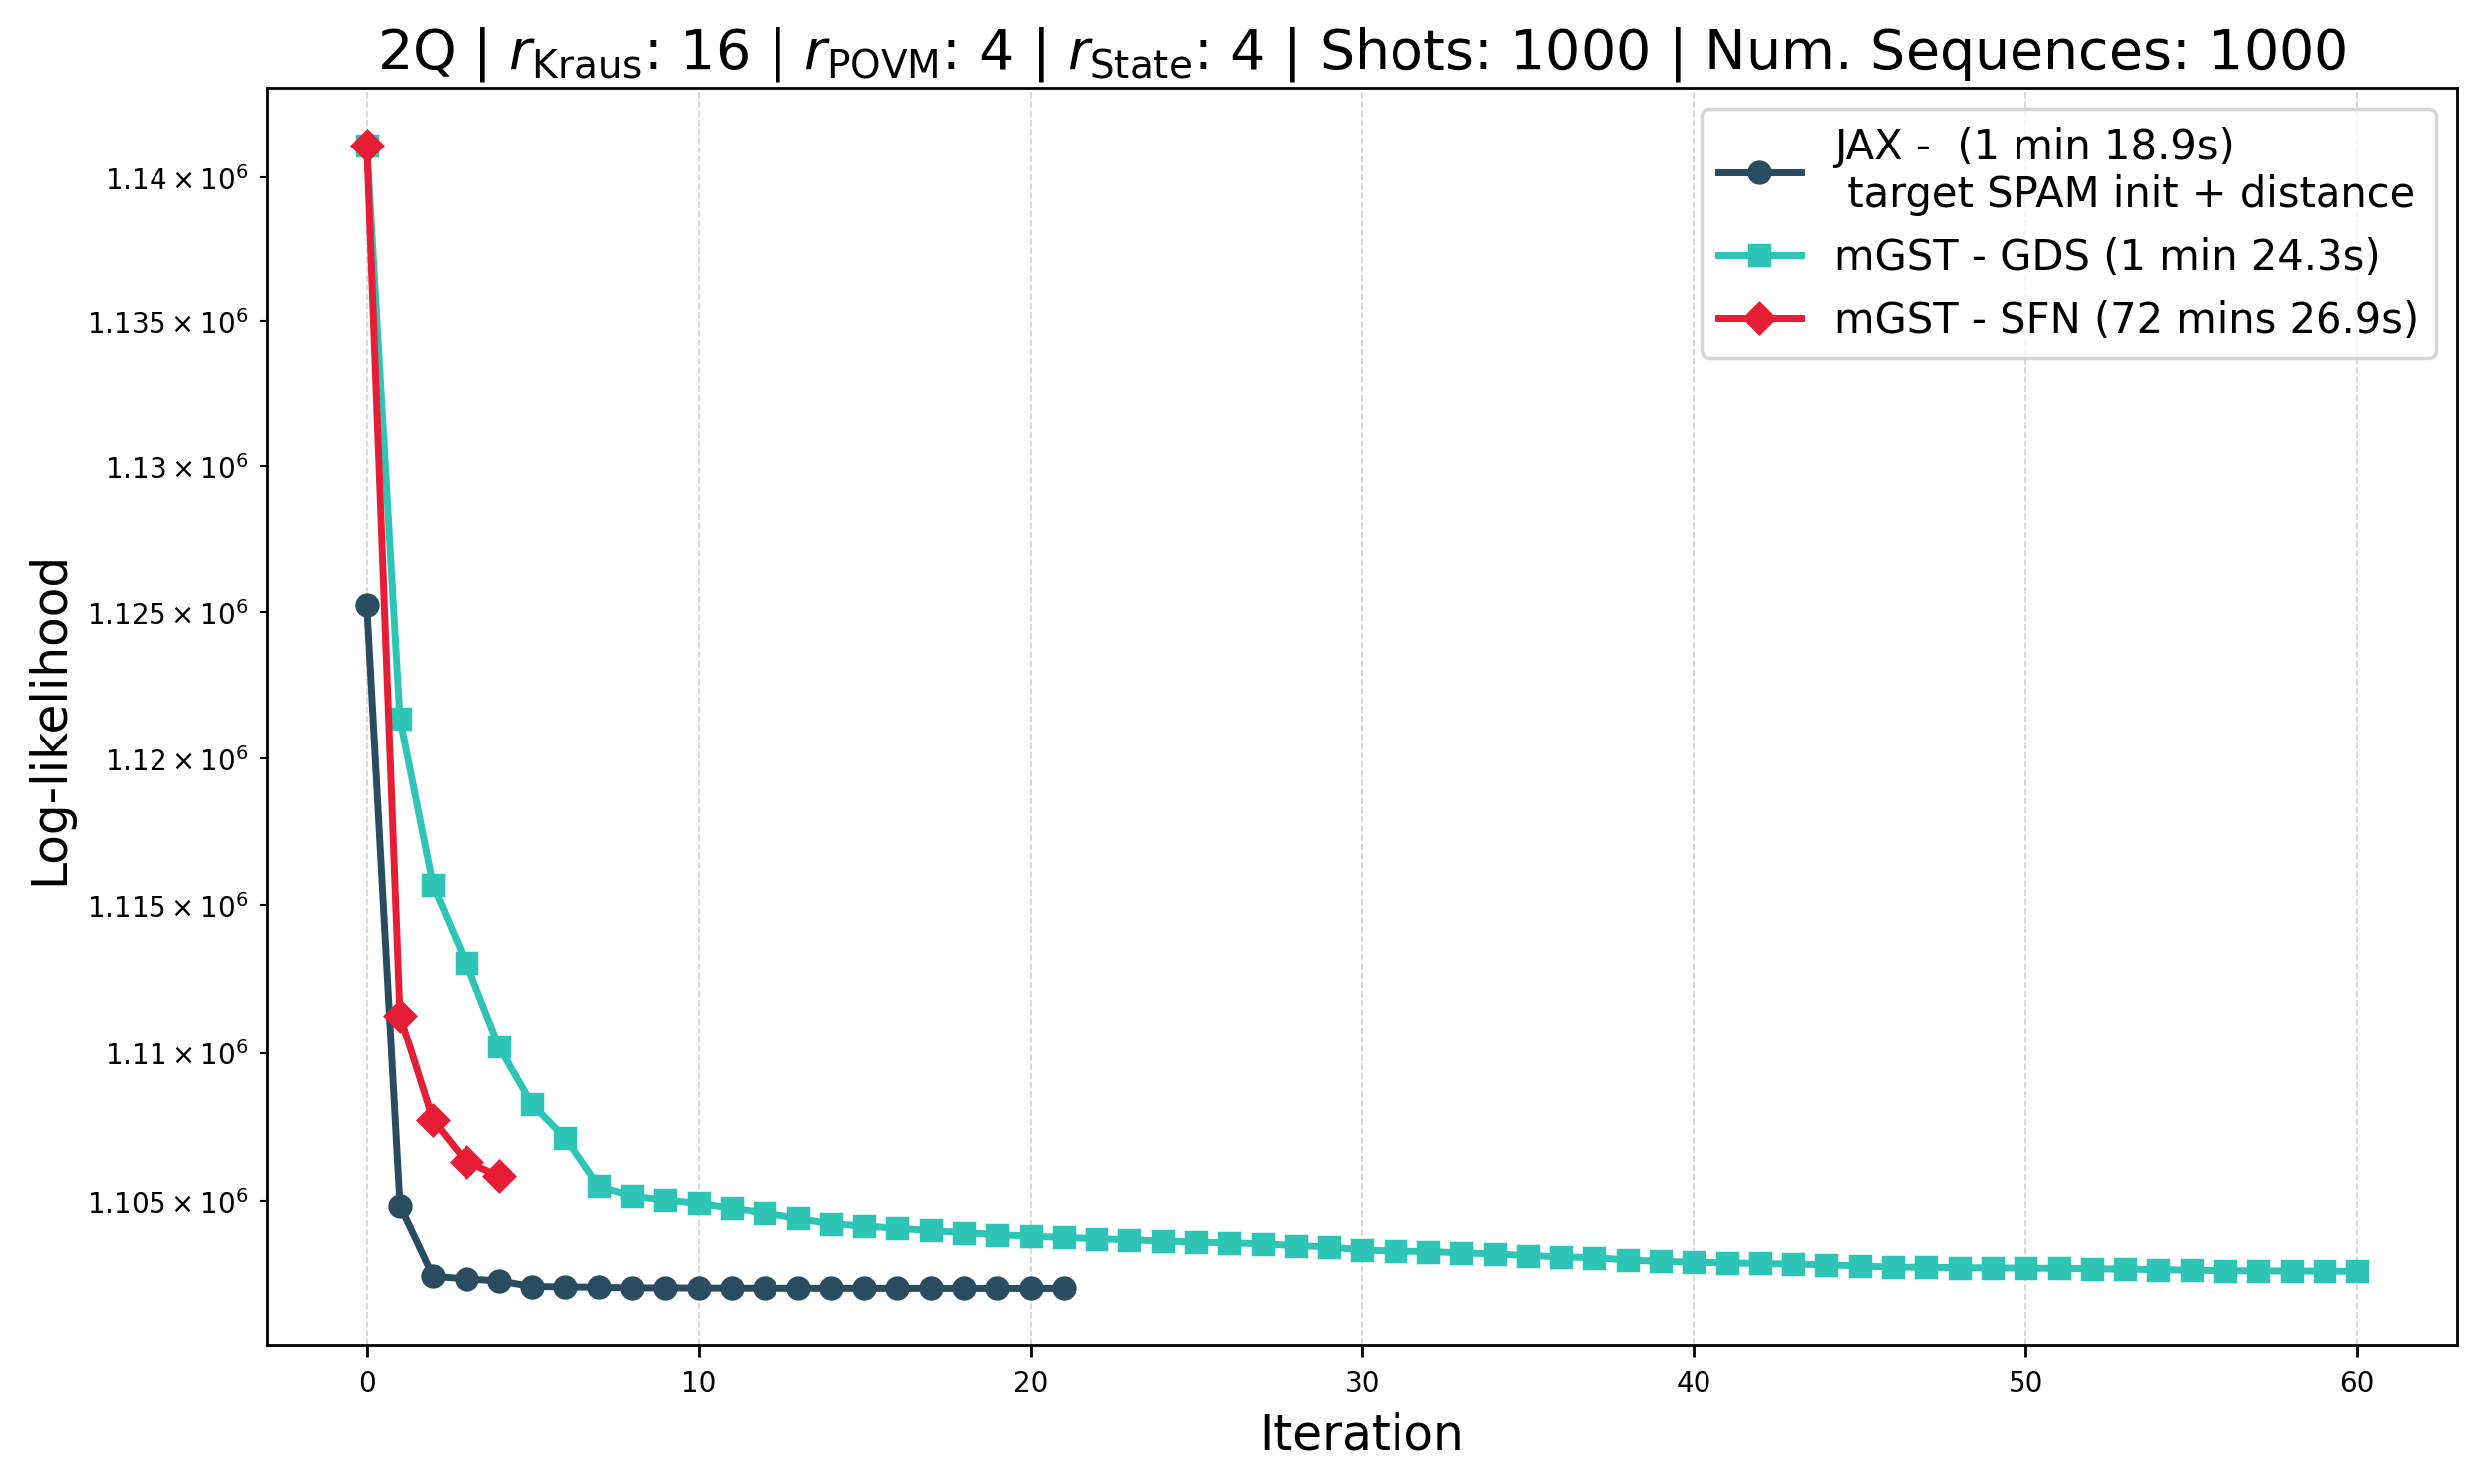

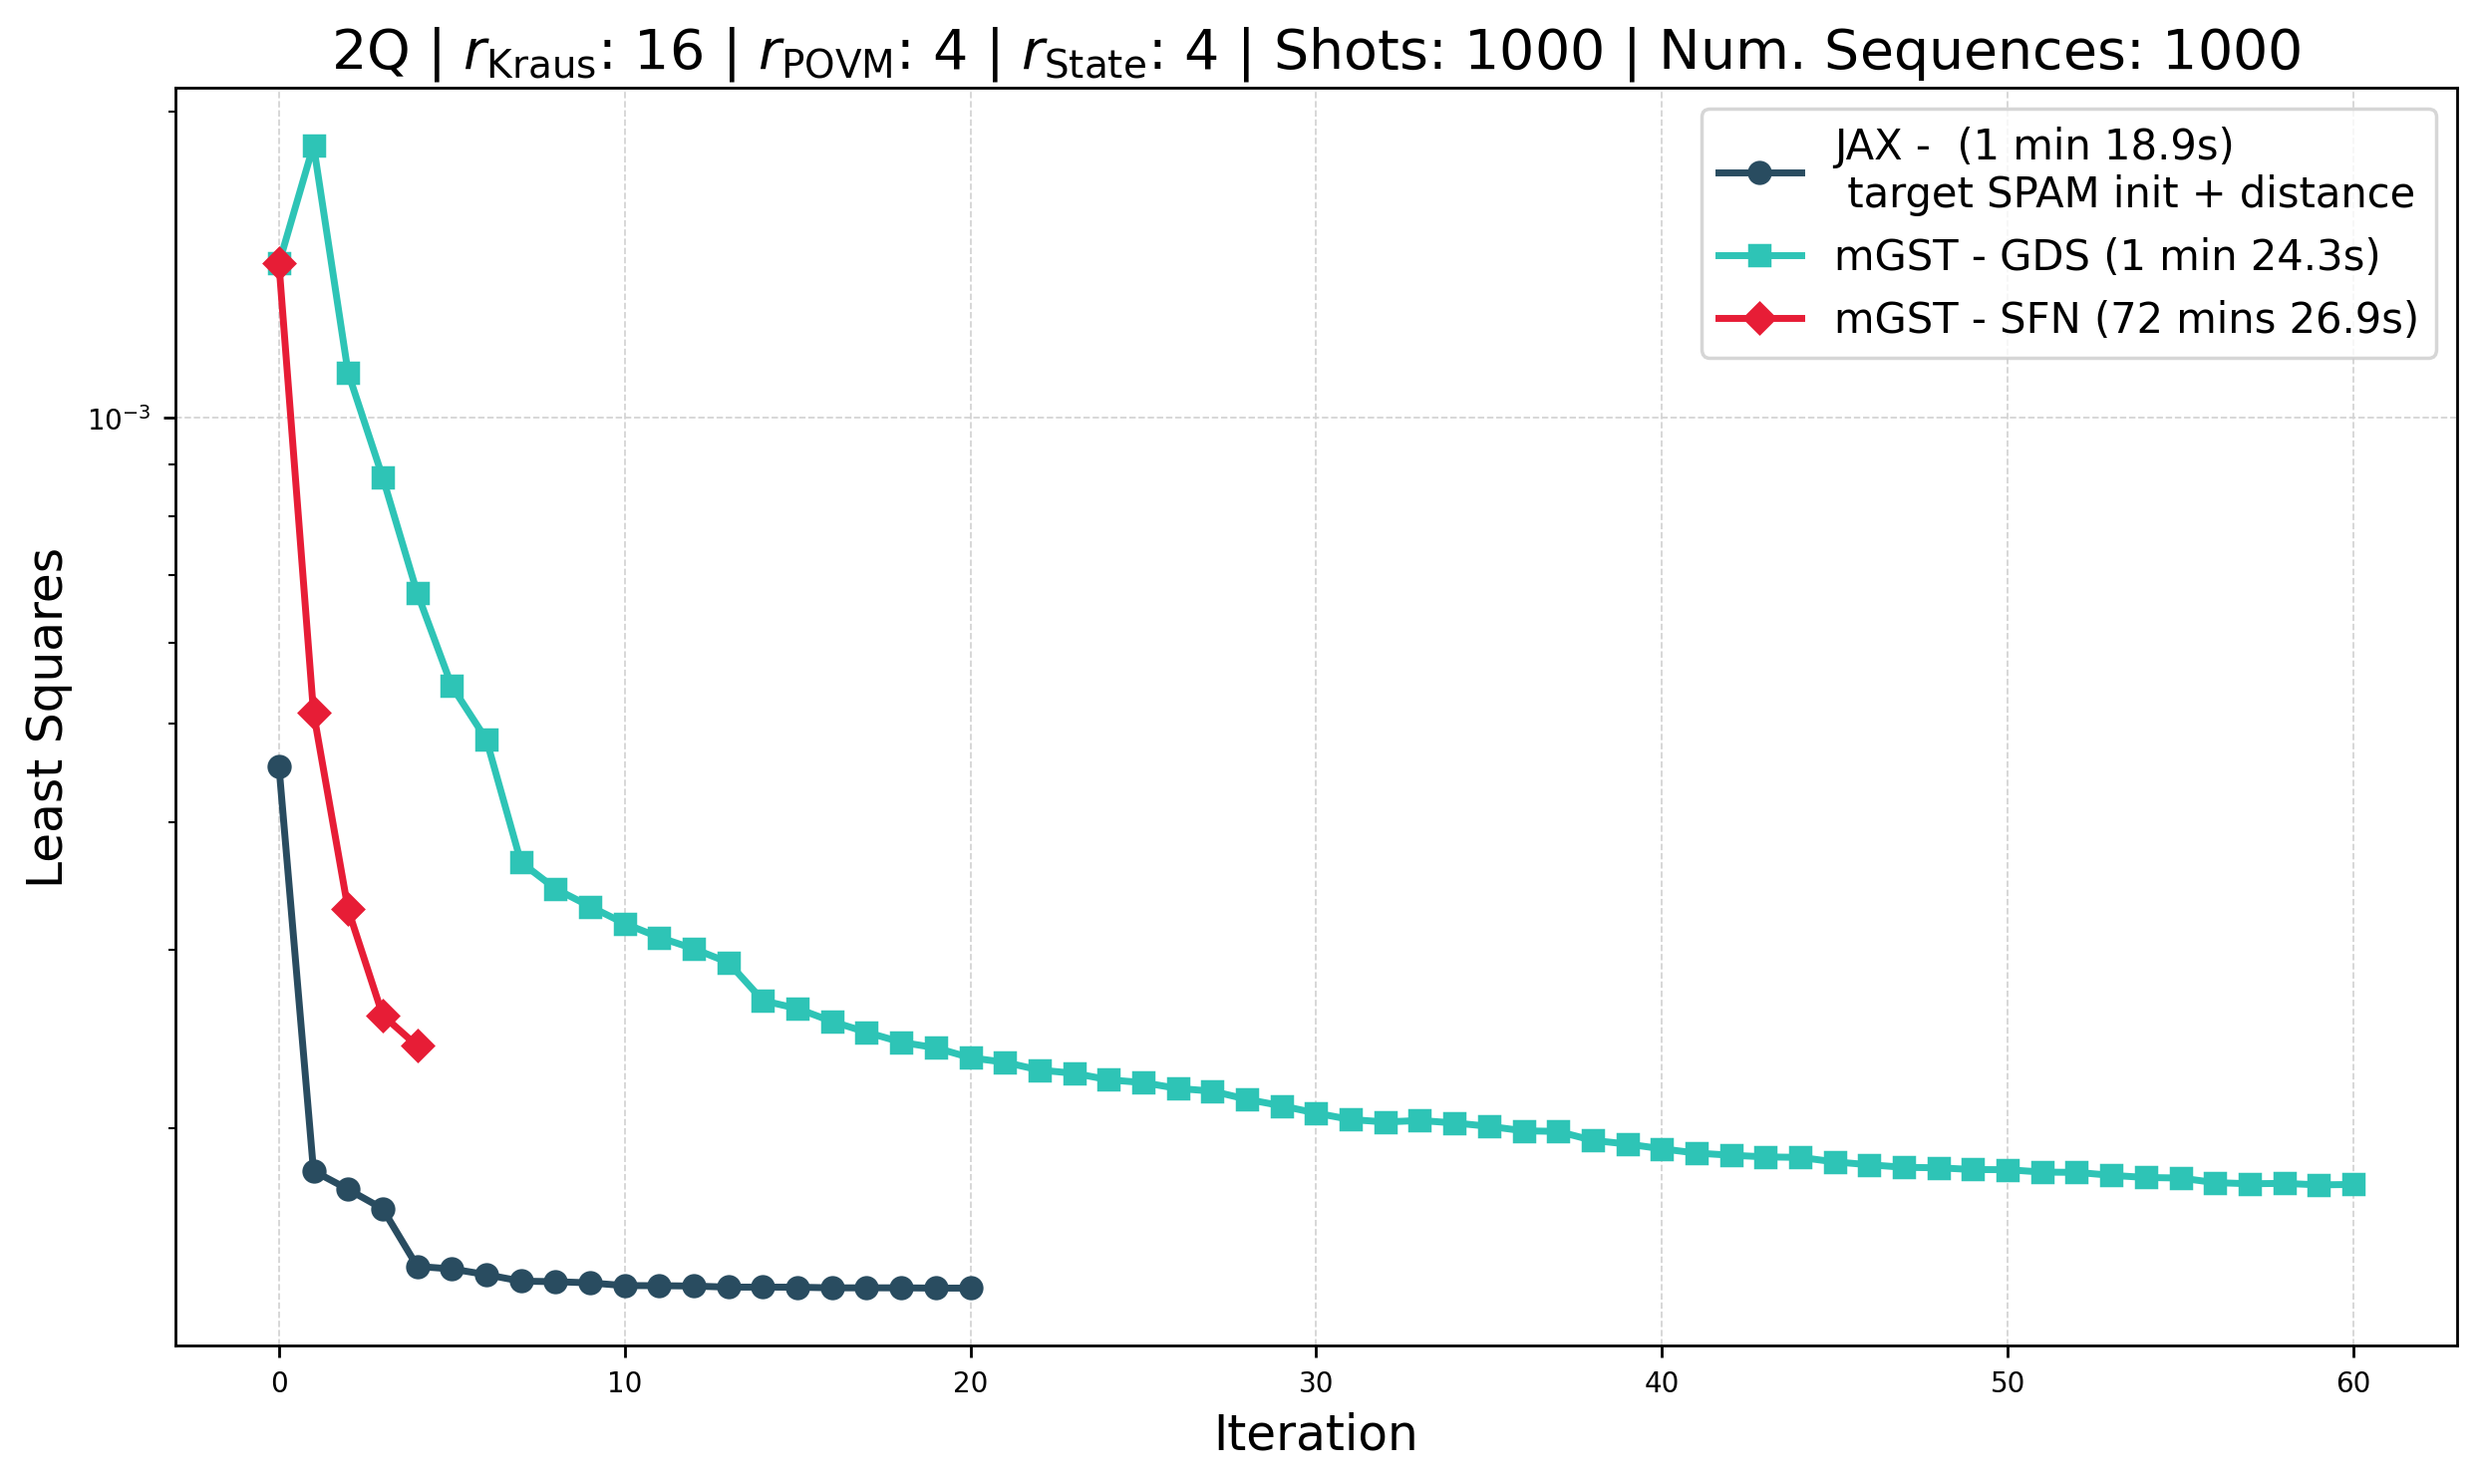

In [101]:
cost_fns_log_likelihood_max = [
    cost_fn_history_max_rank["main"],
    jnp.array(cost_fn_history_mgst_max_gds["log_likelihood"])*num_shots,
    jnp.array(cost_fn_history_mgst_max_sfn["log_likelihood"])*num_shots

]
cost_fns_least_squares_max= [
    cost_fn_history_max_rank["least_squares"],
    cost_fn_history_mgst_max_gds["least_squares"],
    cost_fn_history_mgst_max_sfn["least_squares"]
]
labels_interior_max = [
    "JAX -  (1 min 18.9s) \n target SPAM init + distance",
    "mGST - GDS (1 min 24.3s)",
    "mGST - SFN (72 mins 26.9s)"
]

plot_cost_function(cost_fns_log_likelihood_max, title=title_max, labels=labels_interior_max, ylabel="Log-likelihood")
plot_cost_function(cost_fns_least_squares_max, title=title_max, labels=labels_interior_max, ylabel="Least Squares")